# Protego — Inference & Evaluation Demo

This notebook shows how to:
1. Load a pretrained **Privacy Protection Texture (PPT)** for a protectee.
2. Apply it to a sample image (pose-invariant 3D warping).
3. Evaluate the **before/after retrieval recall** on the preprocessed FaceScrub subset.

Make sure you have run `bash setup_quick.sh`, activated the `protego` environment.

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
import warnings
warnings.filterwarnings("ignore")

import torch
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
import torch.nn.functional as F
import matplotlib.pyplot as plt

from protego import BASE_PATH
from protego.utils import load_mask, load_imgs, crop_face
from protego.UVMapping import UVGenerator
from protego.FaceDetection import FD

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda:0


## 1. Load the pretrained PPT and the UV mapper

The PPT is a universal mask in UV space saved as `univ_mask.npy` under `experiments/<exp_name>/<protectee>/`. The `UVGenerator` (SMIRK + FLAME + MediaPipe) deforms it to match the pose/expression of any face image of the user.

In [2]:
protectee = 'Bradley_Cooper'
exp_name = 'default'
epsilon = 16 / 255.
use_bin_mask = True
three_d = True

mask_path = os.path.join(BASE_PATH, 'experiments', exp_name, protectee, 'univ_mask.npy')
assert os.path.exists(mask_path), f'PPT not found at {mask_path}. Download the demo PPT (DRIVE_LINK__DEMO_PPT).'
mask = load_mask(mask_path=mask_path, device=device)
print('Loaded PPT with shape', tuple(mask.shape))

smirk_base_path = os.path.join(BASE_PATH, 'smirk')
uvmapper = UVGenerator(
    smirk_ckpts_path=os.path.join(smirk_base_path, 'pretrained_models/SMIRK_em1.pt'),
    smirk_base_path=smirk_base_path,
    mp_ldmk_model_path=os.path.join(smirk_base_path, 'assets/face_landmarker.task'),
    device=device,
)

Loaded PPT with shape (1, 3, 224, 224)


Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Using generic FLAME model


I0000 00:00:1780604825.659021 2710912 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1780604825.710356 2711299 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.90.07), renderer: NVIDIA RTX 5880 Ada Generation/PCIe/SSE2
W0000 00:00:1780604825.710755 2710912 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 2a. Apply the PPT to a sample image

We detect and crop the face in the image, deform the PPT to that frame's pose/expression, blend the perturbation back into the original frame, and write a protected image.

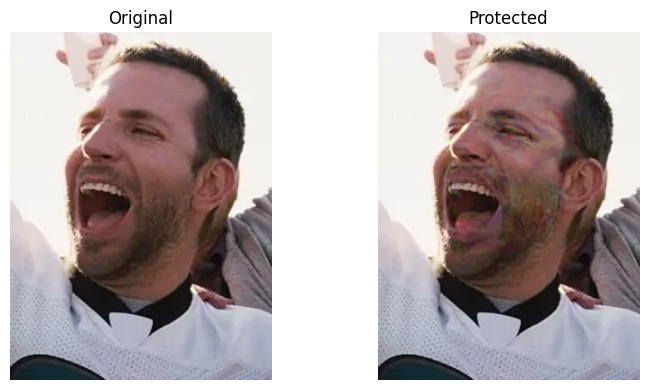

In [3]:
@torch.no_grad()
def protect(face: torch.Tensor) -> torch.Tensor:
    """face: [1, 3, 224, 224], range [0, 1]. Returns the protected image in [0, 1]."""
    uv, bin_mask, _ = uvmapper.forward(imgs=face, align_ldmks=False, batch_size=-1)
    pert = F.grid_sample(mask, uv, align_corners=True, mode='bilinear') if three_d else mask
    if use_bin_mask:
        pert = pert * bin_mask
    pert = pert.clamp(-epsilon, epsilon)
    pert = F.interpolate(pert, size=face.shape[2:], mode='bilinear', align_corners=True)
    return (face + pert).clamp(0., 1.)

with torch.no_grad():
    sample_dir = os.path.join(BASE_PATH, 'face_db', 'imgs', protectee)
    sample_paths = sorted([os.path.join(sample_dir, f) for f in os.listdir(sample_dir)
                        if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')) and not f.startswith(('.', '_'))])
    orig = load_imgs(img_paths=sample_paths[:1], img_sz=-1, drange=255, device=device)[0].div(255.)
    fd = FD('mtcnn', device=device)
    orig_face, (x1, y1, x2, y2) = crop_face(orig[0], fd, verbose=False)
    prot_face = protect(orig_face.unsqueeze_(0))
    prot = orig.clone()
    prot[:, :, y1:y2, x1:x2] = prot_face

    prot_save = (prot[0].permute(1, 2, 0).cpu().numpy() * 255).astype('uint8')
    save_path = os.path.join(BASE_PATH, 'results', 'imgs', protectee)
    os.makedirs(save_path, exist_ok=True)
    plt.imsave(os.path.join(save_path, f'{protectee}_protected.png'), prot_save)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(orig[0].permute(1, 2, 0).cpu().numpy()); axes[0].set_title('Original'); axes[0].axis('off')
    axes[1].imshow(prot[0].permute(1, 2, 0).cpu().numpy()); axes[1].set_title('Protected'); axes[1].axis('off')
    plt.tight_layout(); plt.show()


## 2b. Apply the PPT to a sample video

Protego shines on video, where per-frame consistency keeps the result natural. The logic is the same as above, but we loop through all frames of a video, apply the PPT, and write out a protected video.

In [4]:
import cv2
import time
import shutil
import base64
import subprocess
from IPython.display import HTML, display

# A short sample clip of the protectee. Swap in your own video if you like.
src_vid_path = os.path.join(BASE_PATH, 'face_db', 'vids', protectee, 'bc1.mp4')
out_dir = os.path.join(BASE_PATH, 'results', 'vids', protectee)
os.makedirs(out_dir, exist_ok=True)
orig_vid_path = os.path.join(out_dir, 'original_demo.mp4')
prot_vid_path = os.path.join(out_dir, 'protected_demo.mp4')
pert_vid_path = os.path.join(out_dir, 'perturbation_demo.mp4')
assert os.path.exists(src_vid_path), f'Video not found at {src_vid_path}.'

def _to_bgr_frame(frame_pt: torch.Tensor):
    """RGB float [0,1], shape [3, H, W] -> BGR uint8 [H, W, 3] for cv2 writing."""
    return frame_pt.permute(1, 2, 0).mul(255.).clamp_(0., 255.).to(torch.uint8)[:, :, [2, 1, 0]].cpu().contiguous().numpy()

@torch.no_grad()
def protect_video(src_path: str, orig_path: str, prot_path: str, pert_path: str, pert_amplify: float = 10.) -> None:
    """Protect a video and write three outputs: the original, the protected video, and an
    amplified perturbation visualization (gray = no change)."""
    reader = cv2.VideoCapture(src_path)
    fps = reader.get(cv2.CAP_PROP_FPS)
    width = int(reader.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(reader.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    orig_writer = cv2.VideoWriter(orig_path, fourcc, fps, (width, height))
    prot_writer = cv2.VideoWriter(prot_path, fourcc, fps, (width, height))
    pert_writer = cv2.VideoWriter(pert_path, fourcc, fps, (width, height))
    frame_cnt = 0
    while True:
        ret, frame = reader.read()
        if not ret:
            break
        frame_cnt += 1
        # BGR uint8 -> RGB float [0,1], shape [3, H, W]
        frame_pt = torch.tensor(frame, dtype=torch.float32, device=device).permute(2, 0, 1).div(255.)[[2, 1, 0], :, :]
        pert_frame = torch.full_like(frame_pt, 0.5)  # neutral gray background
        cropped_face, face_pos = crop_face(img=frame_pt, detector=fd, crop_loosen=1., verbose=False, strict=False)
        if cropped_face is not None and face_pos is not None:
            face_pos = list(face_pos)
            fh, fw = cropped_face.shape[1], cropped_face.shape[2]
            resized = F.interpolate(cropped_face.unsqueeze(0), size=(224, 224), mode='bilinear', align_corners=False)
            uv, bin_mask, _ = uvmapper.forward(imgs=resized, align_ldmks=False, batch_size=-1)
            pert = F.grid_sample(mask, uv, align_corners=True, mode='bilinear') if three_d else mask
            if use_bin_mask:
                pert = pert * bin_mask
            pert = F.interpolate(pert, size=(fh, fw), mode='bilinear', align_corners=False).clamp_(-epsilon, epsilon)
            pert = pert.squeeze(0)
            protected_face = (cropped_face + pert).clamp_(0., 1.)
            frame_pt[:, face_pos[1]:face_pos[3], face_pos[0]:face_pos[2]] = protected_face.contiguous()
            # Perturbation visualization: amplify and center around 0.5 (gray)
            pert_vis = (pert * pert_amplify + 0.5).clamp_(0., 1.)
            pert_frame[:, face_pos[1]:face_pos[3], face_pos[0]:face_pos[2]] = pert_vis.contiguous()
            prot_writer.write(_to_bgr_frame(frame_pt))
            pert_writer.write(_to_bgr_frame(pert_frame))
            orig_writer.write(frame.astype('uint8'))  # original frame as-is (already BGR uint8)
            if frame_cnt % 50 == 0:
                print(f'Processed {frame_cnt} frames...')
    reader.release()
    orig_writer.release()
    prot_writer.release()
    pert_writer.release()
    print(f'Done. Protected video saved to {os.path.relpath(prot_path, start=BASE_PATH)}')

def to_h264(path: str) -> str:
    """Re-encode an mp4 to H.264/yuv420p so browsers can play it inline.

    OpenCV's `mp4v` (MPEG-4 Part 2) FourCC is not decodable by the HTML5
    <video> element, so the inline player stays blank. We transcode to H.264
    with ffmpeg and move the moov atom to the front for instant playback.
    """
    if shutil.which('ffmpeg') is None:
        print('ffmpeg not found; returning original (may not play inline).')
        return path
    h264_path = path.replace('.mp4', '_h264.mp4')
    subprocess.run(
        ['ffmpeg', '-y', '-i', path, '-c:v', 'libx264',
         '-pix_fmt', 'yuv420p', '-movflags', '+faststart', h264_path],
        check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )
    return h264_path

def _video_cell(path: str, title: str, cls: str, width: int = 280) -> str:
    """Build an HTML snippet that embeds a video with a caption.

    Videos are `autoplay muted loop` (browsers only autoplay muted clips) and
    share a CSS class so a small script can start them in sync.
    """
    with open(path, 'rb') as f:
        b64 = base64.b64encode(f.read()).decode()
    return (
        f'<div style="text-align:center;margin:0 8px">'
        f'<div style="font-weight:bold;margin-bottom:4px">{title}</div>'
        f'<video class="{cls}" width="{width}" controls autoplay muted loop playsinline>'
        f'<source src="data:video/mp4;base64,{b64}" type="video/mp4"></video></div>'
    )

protect_video(src_vid_path, orig_vid_path, prot_vid_path, pert_vid_path)
orig_h264 = to_h264(orig_vid_path)
prot_h264 = to_h264(prot_vid_path)
pert_h264 = to_h264(pert_vid_path)

# A unique class so the sync script only targets this output's videos.
sync_cls = f'protego-sync-{os.getpid()}-{int(time.time())}'
sync_js = (
    '<script>(function(){'
    f'var vids=document.querySelectorAll("video.{sync_cls}");'
    'function play(){vids.forEach(function(v){v.currentTime=0;v.play();});}'
    'var ready=0;vids.forEach(function(v){'
    'v.addEventListener("loadeddata",function(){ready++;if(ready===vids.length)play();});});'
    '})();</script>'
)

display(HTML(
    '<div style="display:flex;justify-content:center;align-items:flex-start">'
    + _video_cell(orig_h264, '1. Original', sync_cls)
    + _video_cell(prot_h264, '2. Protected', sync_cls)
    + _video_cell(pert_h264, '3. Perturbation', sync_cls)
    + '</div>'
    + sync_js
))

# The H.264 bytes are now base64-embedded in the notebook output, so the
# temporary transcoded files are no longer needed for playback.
for _p in (orig_h264, prot_h264, pert_h264):
    if _p.endswith('_h264.mp4') and os.path.exists(_p):
        os.remove(_p)


Processed 50 frames...


Processed 100 frames...
Processed 150 frames...
Processed 200 frames...
Processed 250 frames...
Processed 300 frames...
Processed 350 frames...
Processed 400 frames...
Processed 450 frames...
Processed 500 frames...
Processed 550 frames...
Processed 600 frames...
Processed 650 frames...
Processed 750 frames...
Processed 800 frames...
Processed 850 frames...
Processed 900 frames...
Processed 950 frames...
Processed 1000 frames...
Processed 1050 frames...
Processed 1100 frames...
Processed 1150 frames...
Processed 1200 frames...
Image 0 has no faces detected in PNet.
Image 0 has no faces detected in PNet.
Image 0 has no faces detected in PNet.
Image 0 has no faces detected in PNet.
Image 0 has no faces detected in PNet.
Done. Protected video saved to results/vids/Bradley_Cooper/protected_demo.mp4


## 3. Evaluate retrieval recall (before vs. after protection)

We reuse the standard pipeline in eval mode. It deforms each protectee's PPT onto their evaluation images, builds the FaceScrub noise/retrieval gallery (augmented with the other protectees' protected features), and reports the retrieval recalls. Keys: `1b` is the unprotected baseline recall (should be high), `1a`/`2a`/`2b` are the protected recalls (lower is better).

In [10]:
import math
from omegaconf import OmegaConf
from protego.utils import get_usable_img_paths
from protego.run_exp import run

configs = {
    'device': str(device),
    'exp_name': 'demo_eval',
    'need_cropping': False, 'fd_name': 'mtcnn', 'crop_loosen': 1., 'shuffle': False,
    'uv_gen_align_ldmk': False, 'uv_gen_batch': 8,
    'three_d': three_d, 'mask_size': 224, 'bin_mask': use_bin_mask, 'epsilon': epsilon,
    'mask_name': [exp_name, 'univ_mask.npy'], 'eval_db': 'face_scrub',
    'eval_fr_names': ['ir50_adaface_casia'],
    'train_fr_names': [], 'save_univ_mask': False, 'visualize_interval': 15,
    'query_portion': 0.5, 'vis_eval': True, 'lpips_backbone': 'vgg', 'eval_scene': 1
}
cfgs = OmegaConf.create(configs)

# Build the train/eval split for a couple of protectees that have a trained PPT.
eval_data_path = os.path.join(BASE_PATH, 'face_db', cfgs.eval_db)
protectees = sorted([name for name in os.listdir(eval_data_path) if not name.startswith(('.', '_'))])
data = {}
for protectee in protectees:
    protectee_path = os.path.join(eval_data_path, protectee)
    imgs = get_usable_img_paths(protectee_path)
    data[protectee] = {'eval': imgs[math.floor(len(imgs) * 0.6):]}  # use the last 40% of images for evaluation
run(cfgs, mode='eval', data=data)

Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Using generic FLAME model


I0000 00:00:1780608158.509215 2710912 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1780608158.523624 2746358 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.90.07), renderer: NVIDIA RTX 5880 Ada Generation/PCIe/SSE2
W0000 00:00:1780608158.524261 2710912 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.


Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Bradley_Cooper for protectee Bradley_Cooper.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Bruce_Willis for protectee Bruce_Willis.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Christina_Applegate for protectee Christina_Applegate.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Courteney_Cox for protectee Courteney_Cox.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Debra_Messing for protectee Debra_Messing.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Felicity_Huffman for protectee Felicity_Huffman.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Fran_Drescher for protectee Fran_Drescher.
Created directory /data2/zlwang/cvpr2026_pub/ProtegoPlus/results/eval/demo_eval/Geena_Davis for protectee Geena_Davis.
Cr

...

===== Search with unprotected queries =====
Protected entries should not be retrieved as top matches
1A Retrieval accuracy: 0.0048 (lower is better)
Unprotected entries are deemed to be retrieved as top matches
1B Retrieval accuracy: 0.8432 (higher is better)
===== Search with protected queries =====
Protected entries should not be retrieved as top matches
2A Retrieval accuracy: 0.0752 (lower is better)
Unprotected entries should not be retrieved as top matches
2B Retrieval accuracy: 0.0192 (lower is better)

##################################################
Evaluating under Eval Scene 1 for Protectee: Sarah_Hyland (19/20)
##################################################

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /home/zlwang/miniforge3/envs/protego/lib/python3.9/site-packages/lpips/weights/v0.1/vgg.pth


Applying mask, extracting features, and evaluating visual quality: 100%|██████████| 3/3 [00:00<00:00,  9.80it/s]


===== Search with unprotected queries =====
Protected entries should not be retrieved as top matches
1A Retrieval accuracy: 0.1245 (lower is better)
Unprotected entries are deemed to be retrieved as top matches
1B Retrieval accuracy: 0.9407 (higher is better)
===== Search with protected queries =====
Protected entries should not be retrieved as top matches
2A Retrieval accuracy: 0.1265 (lower is better)
Unprotected entries should not be retrieved as top matches
2B Retrieval accuracy: 0.1304 (lower is better)

##################################################
Evaluating under Eval Scene 1 for Protectee: Sarah_Michelle_Gellar (20/20)
##################################################

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /home/zlwang/miniforge3/envs/protego/lib/python3.9/site-packages/lpips/weights/v0.1/vgg.pth


Applying mask, extracting features, and evaluating visual quality: 100%|██████████| 3/3 [00:00<00:00,  9.20it/s]


===== Search with unprotected queries =====
Protected entries should not be retrieved as top matches
1A Retrieval accuracy: 0.0191 (lower is better)
Unprotected entries are deemed to be retrieved as top matches
1B Retrieval accuracy: 0.5052 (higher is better)
===== Search with protected queries =====
Protected entries should not be retrieved as top matches
2A Retrieval accuracy: 0.0382 (lower is better)
Unprotected entries should not be retrieved as top matches
2B Retrieval accuracy: 0.0347 (lower is better)


## 4. Visualize the evaluation as a bar chart

The eval run above writes one `eval_res_<fr>.yaml` per protectee under `results/eval/<exp_name>/`. Here we aggregate those across every protectee and draw, for each FR, the average retrieval recall in each scenario:

- **1a** — clean query against a protected gallery
- **2b** — protected query against a clean gallery
- **2a** — protected query against a protected gallery

The red dashed line is the unprotected **FR baseline** (`1b`). Lower protected bars mean stronger protection. The chart is also saved as a PNG next to the YAMLs.

Results for ir50_adaface_casia (averaged over 20 protectees):
  Clean Query & Protected DB: 0.0384
  FR Baseline Performance: 0.7086
  Protected Query & Protected DB: 0.0851
  Protected Query & Clean DB: 0.0509
  SSIM: 0.9381
  PSNR: 32.0696
  L0: 0.6993
  LPIPS: 0.1286


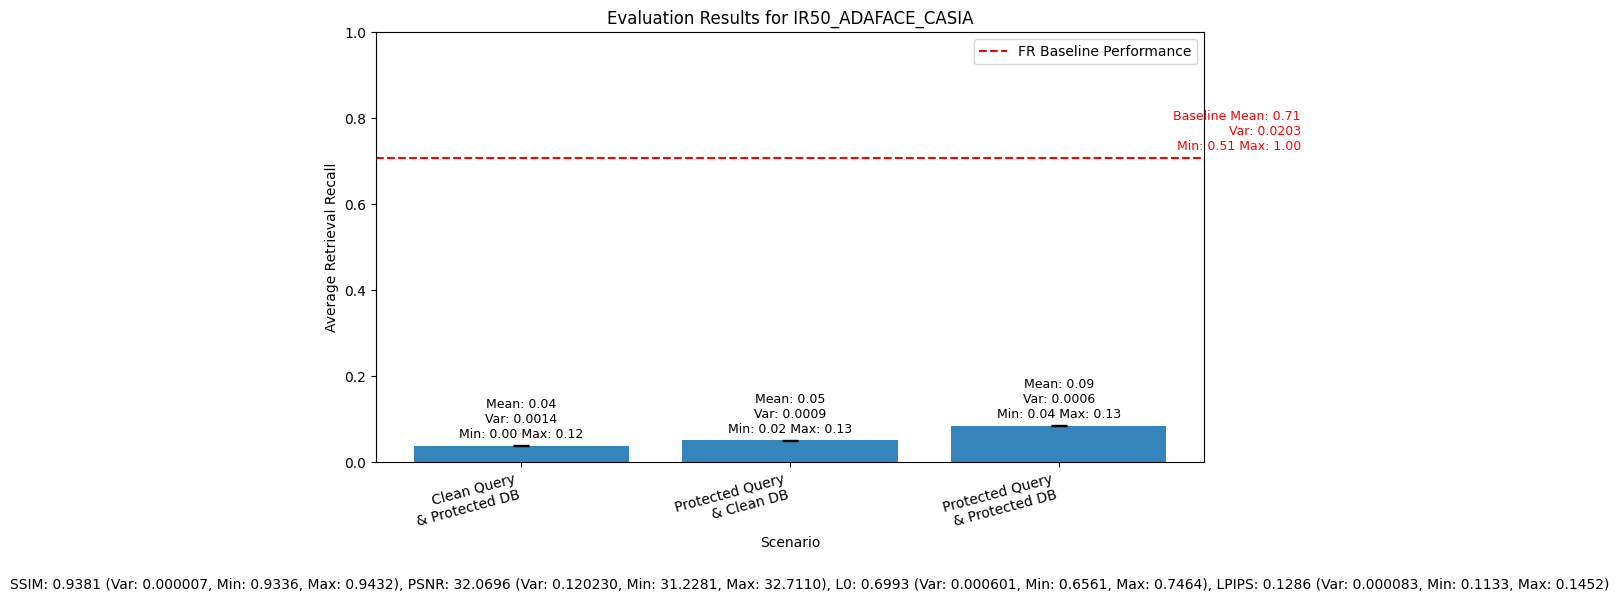

In [11]:
import yaml
import numpy as np

name_mapping = {
    '1a': 'Clean Query\n& Protected DB',
    '2b': 'Protected Query\n& Clean DB',
    '2a': 'Protected Query\n& Protected DB',
    '1b': 'FR Baseline Performance',
}


def _safe_load_yaml(file_path: str):
    if not os.path.exists(file_path):
        return None
    try:
        with open(file_path, 'r') as f:
            return yaml.safe_load(f)
    except Exception:
        return None


def _discover_fr_names(user_dir: str) -> list:
    """Infer FR names from result filenames when cfgs.yaml is missing."""
    fr_names = []
    try:
        for fname in os.listdir(user_dir):
            if fname.startswith('eval_res_') and fname.endswith('.yaml'):
                fr_names.append(fname.replace('eval_res_', '').replace('.yaml', ''))
    except Exception:
        pass
    return sorted(set(fr_names))


def ana_res(eval_name: str, use_lpips: bool = True, save: bool = True):
    """Aggregate the per-protectee eval YAMLs and plot a retrieval-recall bar chart per FR.

    Args:
        eval_name: subfolder name under results/eval/ that holds the protectee result folders.
        use_lpips: include the LPIPS metric.
        save: also write the figure as a PNG next to the YAMLs.
    """
    res_path = os.path.join(BASE_PATH, 'results', 'eval', eval_name)
    if not os.path.isdir(res_path):
        raise FileNotFoundError(f'Result path not found: {res_path}')

    user_names = [
        name for name in os.listdir(res_path)
        if not name.startswith(('.', '_')) and os.path.isdir(os.path.join(res_path, name))
    ]
    if not user_names:
        raise RuntimeError(f'No protectee folders found under {res_path}')

    # FR list: prefer cfgs.yaml, otherwise infer from the result filenames.
    cfgs_yaml = _safe_load_yaml(os.path.join(res_path, user_names[0], 'cfgs.yaml')) or {}
    test_frs = cfgs_yaml.get('eval_fr_names') or _discover_fr_names(
        os.path.join(res_path, user_names[0]))
    if not test_frs:
        raise RuntimeError('Cannot determine FR names: no cfgs.yaml and no eval result files.')

    bar_keys = ['1a', '2b', '2a']
    bar_labels = [name_mapping[k] for k in bar_keys]

    for fr_name in test_frs:
        scenario_keys = ['1a', '1b', '2a', '2b']
        metrics_keys = ['ssim', 'psnr', 'l0'] + (['lpips'] if use_lpips else [])
        res_filename = f'eval_res_{fr_name}.yaml'

        res_recorder = {k: [] for k in scenario_keys + metrics_keys}

        # Aggregate results across the protectee folders.
        for user_name in user_names:
            user_path = os.path.join(res_path, user_name)
            user_res = _safe_load_yaml(os.path.join(user_path, res_filename)) or {}
            for key in scenario_keys + metrics_keys:
                if key in user_res:
                    res_recorder[key].append(user_res[key])

        print(f'Results for {fr_name} (averaged over {len(user_names)} protectees):')
        for key, values in res_recorder.items():
            if values:
                label = key.upper() if key in metrics_keys else name_mapping.get(key, key).replace('\n', ' ')
                print(f'  {label}: {np.mean(values):.4f}')

        # ---- Scenario bar chart ----
        bar_values = [np.mean(res_recorder[k]) if res_recorder[k] else 0 for k in bar_keys]
        bar_vars = [np.var(res_recorder[k]) if res_recorder[k] else 0 for k in bar_keys]
        bar_mins = [np.min(res_recorder[k]) if res_recorder[k] else 0 for k in bar_keys]
        bar_maxs = [np.max(res_recorder[k]) if res_recorder[k] else 0 for k in bar_keys]

        plt.figure(figsize=(10, 6))
        plt.bar(bar_labels, bar_values, yerr=bar_vars, capsize=6, alpha=0.9)
        for i, (value, var_val, min_val, max_val) in enumerate(zip(bar_values, bar_vars, bar_mins, bar_maxs)):
            plt.text(i, value + 0.01,
                     f'Mean: {value:.2f}\nVar: {var_val:.4f}\nMin: {min_val:.2f} Max: {max_val:.2f}',
                     ha='center', va='bottom', fontsize=9)
        plt.title(f'Evaluation Results for {fr_name.upper()}')
        plt.xlabel('Scenario')
        plt.ylabel('Average Retrieval Recall')
        plt.xticks(rotation=15, ha='right')
        plt.ylim(0, 1)

        baseline = res_recorder['1b']
        baseline_mean = np.mean(baseline) if baseline else 0
        plt.axhline(y=baseline_mean, color='r', linestyle='--', label='FR Baseline Performance')
        if baseline:
            plt.text(len(bar_labels) - 0.1, baseline_mean + 0.01,
                     f'Baseline Mean: {baseline_mean:.2f}\nVar: {np.var(baseline):.4f}\n'
                     f'Min: {np.min(baseline):.2f} Max: {np.max(baseline):.2f}',
                     color='r', ha='right', va='bottom', fontsize=9)

        metric_stats_parts = []
        for mk in metrics_keys:
            if res_recorder[mk]:
                v = res_recorder[mk]
                metric_stats_parts.append(
                    f'{mk.upper()}: {np.mean(v):.4f} (Var: {np.var(v):.6f}, '
                    f'Min: {np.min(v):.4f}, Max: {np.max(v):.4f})')
        if metric_stats_parts:
            plt.figtext(0.5, 0.01, ', '.join(metric_stats_parts), ha='center', fontsize=10)
        plt.tight_layout(rect=[0, 0.05, 1, 1])
        plt.legend()
        if save:
            plt.savefig(os.path.join(res_path, f'{fr_name}_evaluation_results.png'))
        plt.show()


# run() above appends a timestamp to exp_name if 'demo_eval' already existed, so read the
# resolved folder name back from cfgs (fallback to the literal name if cfgs isn't defined yet).
eval_name = cfgs.exp_name if 'cfgs' in globals() else 'demo_eval'
ana_res(eval_name=eval_name, use_lpips=True)